In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:

import os

print("Available dataset folders:")
print(os.listdir("/kaggle/input"))

print("\nFinding CSV files:")
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


Available dataset folders:
['datasets']

Finding CSV files:
/kaggle/input/datasets/nirenjanamp/student-record-train/train (1).csv


In [5]:

import pandas as pd
import numpy as np

# Load the training dataset
df = pd.read_csv(
    "/kaggle/input/datasets/nirenjanamp/student-record-train/train (1).csv"
)

# Display dataset details
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

# Display the first five rows
display(df.head())


Dataset loaded successfully!
Number of rows and columns: (7225, 11)


,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
0,7.7,1,1,0,69,4.0,No,No,55,69,NotPlaced
1,7.6,2,3,1,80,4.3,Yes,Yes,57,70,NotPlaced
2,7.0,1,1,1,64,4.1,No,No,58,62,NotPlaced
3,7.9,1,3,2,90,4.8,Yes,Yes,82,80,Placed
4,6.7,0,2,1,71,3.7,No,No,55,67,NotPlaced


In [6]:

# 1. Check column names and data types
print("COLUMN NAMES AND DATA TYPES")
df.info()

# 2. Count missing values in each column
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Count duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# 4. Check the placement outcome distribution
print("\nPLACEMENT STATUS DISTRIBUTION")
print(df["PlacementStatus"].value_counts(dropna=False))


COLUMN NAMES AND DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7225 entries, 0 to 7224
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CGPA                       7225 non-null   float64
 1   Internships                7225 non-null   int64  
 2   Projects                   7225 non-null   int64  
 3   Workshops/Certifications   7225 non-null   int64  
 4   AptitudeTestScore          7225 non-null   int64  
 5   SoftSkillsRating           7225 non-null   float64
 6   ExtracurricularActivities  7225 non-null   object 
 7   PlacementTraining          7225 non-null   object 
 8   SSC_Marks                  7225 non-null   int64  
 9   HSC_Marks                  7225 non-null   int64  
 10  PlacementStatus            7225 non-null   object 
dtypes: float64(2), int64(6), object(3)
memory usage: 621.0+ KB

MISSING VALUES
CGPA                         0
Internships               

In [7]:

# Check and remove exact duplicate rows
print("Rows before removing duplicates:", len(df))

df = df.drop_duplicates().reset_index(drop=True)

print("Rows after removing duplicates:", len(df))
print("Duplicates remaining:", df.duplicated().sum())


Rows before removing duplicates: 7225
Rows after removing duplicates: 7182
Duplicates remaining: 0


In [9]:

# Input features (student information)
X = df.drop(columns=["PlacementStatus"])

# Target variable (placement outcome)
y = df["PlacementStatus"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nPlacement labels:")
print(y.value_counts())


Feature shape: (7182, 10)
Target shape: (7182,)

Placement labels:
PlacementStatus
NotPlaced    4192
Placed       2990
Name: count, dtype: int64


In [10]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining placement distribution:")
print(y_train.value_counts())

print("\nTesting placement distribution:")
print(y_test.value_counts())


Training records: 5745
Testing records: 1437

Training placement distribution:
PlacementStatus
NotPlaced    3353
Placed       2392
Name: count, dtype: int64

Testing placement distribution:
PlacementStatus
NotPlaced    839
Placed       598
Name: count, dtype: int64


In [11]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

# Encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("\nPreprocessing setup completed!")


Categorical features: ['ExtracurricularActivities', 'PlacementTraining']
Numerical features: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'SSC_Marks', 'HSC_Marks']

Preprocessing setup completed!


In [12]:

# Create the complete machine learning pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

# Train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


Model Accuracy: 0.7891
Model Accuracy: 78.91%

Classification Report:
              precision    recall  f1-score   support

   NotPlaced       0.80      0.85      0.83       839
      Placed       0.77      0.70      0.73       598

    accuracy                           0.79      1437
   macro avg       0.79      0.78      0.78      1437
weighted avg       0.79      0.79      0.79      1437



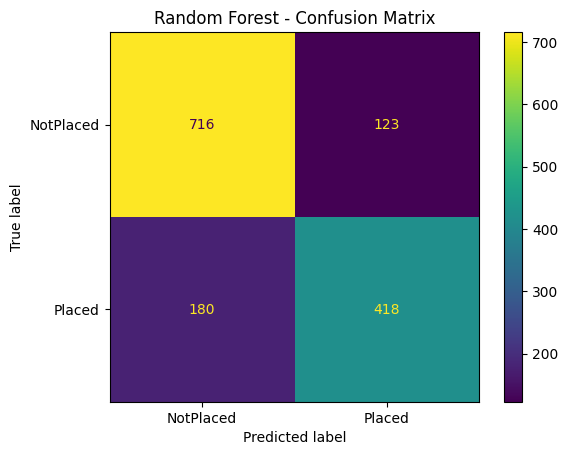

In [13]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict placement outcomes for the test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Detailed performance report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["NotPlaced", "Placed"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["NotPlaced", "Placed"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NotPlaced", "Placed"]
)

display_matrix.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()


Feature importance ranking:


,Feature,Importance
11,numerical__HSC_Marks,0.185915
8,numerical__AptitudeTestScore,0.171448
10,numerical__SSC_Marks,0.133237
4,numerical__CGPA,0.117794
9,numerical__SoftSkillsRating,0.093430
1,categorical__ExtracurricularActivities_Yes,0.062059
0,categorical__ExtracurricularActivities_No,0.061695
6,numerical__Projects,0.058723
7,numerical__Workshops/Certifications,0.054146
5,numerical__Internships,0.033067


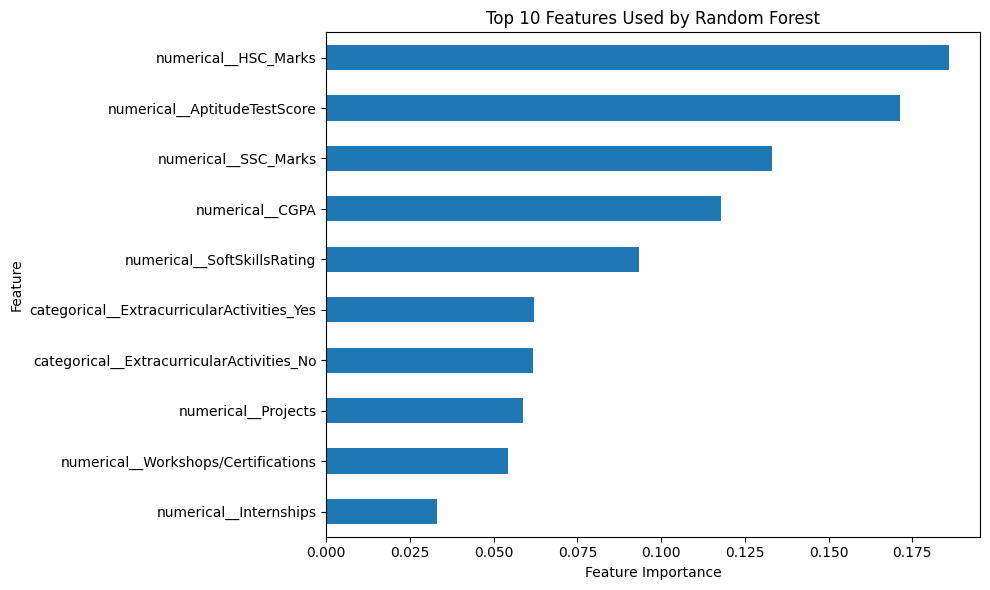

In [14]:

# Extract the trained Random Forest classifier
rf = model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Build the importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("Feature importance ranking:")
display(importance_df)

# Plot the top 10 features
importance_df.head(10).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(10, 6)
)

plt.title("Top 10 Features Used by Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [15]:

# Step 13: Examine student feature distributions

analysis_columns = [
    "CGPA",
    "Internships",
    "Projects",
    "Workshops/Certifications",
    "AptitudeTestScore",
    "SoftSkillsRating",
    "SSC_Marks",
    "HSC_Marks"
]

print("Feature statistics:")
display(df[analysis_columns].describe().T.round(2))


Feature statistics:


,count,mean,std,min,25%,50%,75%,max
CGPA,7182.0,7.70,0.64,6.5,7.4,7.7,8.2,9.1
Internships,7182.0,1.04,0.66,0.0,1.0,1.0,1.0,2.0
Projects,7182.0,2.02,0.87,0.0,1.0,2.0,3.0,3.0
Workshops/Certifications,7182.0,1.01,0.90,0.0,0.0,1.0,2.0,3.0
AptitudeTestScore,7182.0,79.41,8.14,60.0,73.0,80.0,87.0,90.0
SoftSkillsRating,7182.0,4.32,0.41,3.0,4.0,4.4,4.7,4.8
SSC_Marks,7182.0,69.13,10.44,55.0,59.0,70.0,78.0,90.0
HSC_Marks,7182.0,74.40,8.89,57.0,67.0,73.0,83.0,88.0


In [17]:

# Step 14: Skill Gap Analysis and Recommendations

def analyze_skill_gaps(student):
    recommendations = []

    # Academic performance
    if student["CGPA"] < 7.5:
        recommendations.append({
            "Area": "Academic Performance",
            "Observation": f"Your CGPA is {student['CGPA']:.2f}.",
            "Recommendation": (
                "Strengthen core subjects, revise difficult topics, "
                "and follow a consistent study schedule."
            )
        })

    # Aptitude
    if student["AptitudeTestScore"] < 80:
        recommendations.append({
            "Area": "Aptitude",
            "Observation": (
                f"Your aptitude score is "
                f"{student['AptitudeTestScore']:.0f}."
            ),
            "Recommendation": (
                "Practise quantitative aptitude, logical reasoning, "
                "and timed placement questions."
            )
        })

    # Soft skills
    if student["SoftSkillsRating"] < 4.3:
        recommendations.append({
            "Area": "Soft Skills",
            "Observation": (
                f"Your soft skills rating is "
                f"{student['SoftSkillsRating']:.1f}."
            ),
            "Recommendation": (
                "Practise communication, teamwork, interview answers, "
                "and mock group discussions."
            )
        })

    # Projects
    if student["Projects"] < 2:
        recommendations.append({
            "Area": "Projects",
            "Observation": (
                f"You have {int(student['Projects'])} recorded projects."
            ),
            "Recommendation": (
                "Build a practical project related to your career goals "
                "and document your contribution."
            )
        })

    # Internships
    if student["Internships"] < 1:
        recommendations.append({
            "Area": "Internships",
            "Observation": (
                f"You have {int(student['Internships'])} recorded internships."
            ),
            "Recommendation": (
                "Explore internships, virtual work experience, "
                "or relevant practical training opportunities."
            )
        })

    # Workshops and certifications
    if student["Workshops/Certifications"] < 1:
        recommendations.append({
            "Area": "Certifications and Workshops",
            "Observation": (
                f"You have {int(student['Workshops/Certifications'])} "
                "recorded workshops/certifications."
            ),
            "Recommendation": (
                "Consider a relevant course or workshop and apply "
                "what you learn in a practical task."
            )
        })

    # School marks are included as indicators, not as direct skill gaps
    if student["SSC_Marks"] < 65:
        recommendations.append({
            "Area": "SSC Academic Record",
            "Observation": f"Your SSC marks are {student['SSC_Marks']:.0f}.",
            "Recommendation": (
                "Review foundational concepts where needed and highlight "
                "your more recent academic and practical achievements."
            )
        })

    if student["HSC_Marks"] < 70:
        recommendations.append({
            "Area": "HSC Academic Record",
            "Observation": f"Your HSC marks are {student['HSC_Marks']:.0f}.",
            "Recommendation": (
                "Strengthen relevant foundational knowledge and focus "
                "on demonstrating your current abilities."
            )
        })

    if not recommendations:
        recommendations.append({
            "Area": "General Development",
            "Observation": "No gaps were flagged by these initial rules.",
            "Recommendation": (
                "Continue practising, improve your portfolio, and "
                "prepare for interviews."
            )
        })

    return pd.DataFrame(recommendations)

print("Skill-gap recommendation function created successfully.")


Skill-gap recommendation function created successfully.


In [18]:

# Step 15: Test the skill-gap analysis

sample_student = X_test.iloc[0]

print("Student profile:")
display(sample_student.to_frame(name="Value"))

print("Skill-gap recommendations:")
display(analyze_skill_gaps(sample_student))


Student profile:


,Value
CGPA,7.5
Internships,2
Projects,3
Workshops/Certifications,0
AptitudeTestScore,88
SoftSkillsRating,4.6
ExtracurricularActivities,Yes
PlacementTraining,Yes
SSC_Marks,78
HSC_Marks,87


Skill-gap recommendations:


,Area,Observation,Recommendation
0,Certifications and Workshops,You have 0 recorded workshops/certifications.,Consider a relevant course or workshop and app...


In [19]:

# Step 16: Combined Placement Prediction and Skill-Gap Analysis

def assess_student(student):
    # Convert the student profile into a one-row DataFrame
    student_df = student.to_frame().T

    # Predict placement status
    predicted_status = model.predict(student_df)[0]

    # Get predicted class probabilities
    probabilities = model.predict_proba(student_df)[0]
    class_labels = model.named_steps["classifier"].classes_

    probability_by_class = dict(zip(class_labels, probabilities))

    print("===== STUDENT PLACEMENT ASSESSMENT =====")
    print("Predicted Placement Status:", predicted_status)
    print(
        "Predicted placement probability:",
        f"{probability_by_class.get('Placed', 0) * 100:.2f}%"
    )

    print("\n===== SKILL-GAP RECOMMENDATIONS =====")
    recommendations = analyze_skill_gaps(student)
    display(recommendations)

    return predicted_status, probability_by_class, recommendations


# Assess the same student from Step 15
assess_student(sample_student)


===== STUDENT PLACEMENT ASSESSMENT =====
Predicted Placement Status: NotPlaced
Predicted placement probability: 31.00%

===== SKILL-GAP RECOMMENDATIONS =====


,Area,Observation,Recommendation
0,Certifications and Workshops,You have 0 recorded workshops/certifications.,Consider a relevant course or workshop and app...


('NotPlaced',
 {'NotPlaced': np.float64(0.69), 'Placed': np.float64(0.31)},
                            Area  \
 0  Certifications and Workshops   
 
                                      Observation  \
 0  You have 0 recorded workshops/certifications.   
 
                                       Recommendation  
 0  Consider a relevant course or workshop and app...  )

In [20]:

# Step 17: Test a second student profile

student_2 = pd.Series({
    "CGPA": 8.5,
    "Internships": 2,
    "Projects": 3,
    "Workshops/Certifications": 2,
    "AptitudeTestScore": 88,
    "SoftSkillsRating": 4.6,
    "ExtracurricularActivities": "Yes",
    "PlacementTraining": "Yes",
    "SSC_Marks": 82,
    "HSC_Marks": 85
})

assess_student(student_2)


===== STUDENT PLACEMENT ASSESSMENT =====
Predicted Placement Status: Placed
Predicted placement probability: 85.50%

===== SKILL-GAP RECOMMENDATIONS =====


,Area,Observation,Recommendation
0,General Development,No gaps were flagged by these initial rules.,"Continue practising, improve your portfolio, a..."


('Placed',
 {'NotPlaced': np.float64(0.145), 'Placed': np.float64(0.855)},
                   Area                                   Observation  \
 0  General Development  No gaps were flagged by these initial rules.   
 
                                       Recommendation  
 0  Continue practising, improve your portfolio, a...  )

In [21]:

# Step 18: Evaluate multiple test students

results = []

for index in range(10):
    student = X_test.iloc[index]

    predicted_status = model.predict(student.to_frame().T)[0]
    probabilities = model.predict_proba(student.to_frame().T)[0]
    class_labels = model.named_steps["classifier"].classes_
    probability_by_class = dict(zip(class_labels, probabilities))

    recommendations = analyze_skill_gaps(student)

    results.append({
        "Student_ID": f"Test_{index + 1}",
        "Predicted_Status": predicted_status,
        "Placed_Probability_%": round(
            probability_by_class.get("Placed", 0) * 100, 2
        ),
        "Number_of_Recommendations": (
            0 if (
                len(recommendations) == 1
                and recommendations.iloc[0]["Area"] == "General Development"
            )
            else len(recommendations)
        )
    })

results_df = pd.DataFrame(results)

display(results_df)


,Student_ID,Predicted_Status,Placed_Probability_%,Number_of_Recommendations
0,Test_1,NotPlaced,31.0,1
1,Test_2,Placed,86.5,0
2,Test_3,NotPlaced,6.0,4
3,Test_4,Placed,89.0,0
4,Test_5,NotPlaced,0.0,6
5,Test_6,NotPlaced,19.0,3
6,Test_7,Placed,97.5,0
7,Test_8,NotPlaced,15.5,4
8,Test_9,NotPlaced,3.0,5
9,Test_10,Placed,53.5,1


In [23]:

# Step 20: Five-fold stratified cross-validation

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
import pandas as pd

# Use only the training data for cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "placed_precision": make_scorer(
        precision_score, pos_label="Placed", zero_division=0
    ),
    "placed_recall": make_scorer(
        recall_score, pos_label="Placed", zero_division=0
    ),
    "placed_f1": make_scorer(
        f1_score, pos_label="Placed", zero_division=0
    )
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display results for each fold
fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy (%)": cv_results["test_accuracy"] * 100,
    "Placed Precision (%)": cv_results["test_placed_precision"] * 100,
    "Placed Recall (%)": cv_results["test_placed_recall"] * 100,
    "Placed F1 (%)": cv_results["test_placed_f1"] * 100
})

display(fold_results.round(2))

# Summarize mean and variation across folds
print("\nCross-validation summary:")
print(f"Mean accuracy: {cv_results['test_accuracy'].mean() * 100:.2f}%")
print(f"Accuracy standard deviation: {cv_results['test_accuracy'].std() * 100:.2f}%")
print(f"Mean Placed recall: {cv_results['test_placed_recall'].mean() * 100:.2f}%")
print(f"Mean Placed F1-score: {cv_results['test_placed_f1'].mean() * 100:.2f}%")


,Fold,Accuracy (%),Placed Precision (%),Placed Recall (%),Placed F1 (%)
0,1,79.55,76.94,72.59,74.70
1,2,79.11,77.42,70.29,73.68
2,3,78.85,76.40,71.13,73.67
3,4,77.28,75.00,68.27,71.48
4,5,80.77,78.17,74.74,76.41



Cross-validation summary:
Mean accuracy: 79.11%
Accuracy standard deviation: 1.13%
Mean Placed recall: 71.40%
Mean Placed F1-score: 73.99%
